### Bar Chart – Vaccination % vs New Deaths per Million

File loaded successfully with shape: (75359, 13)


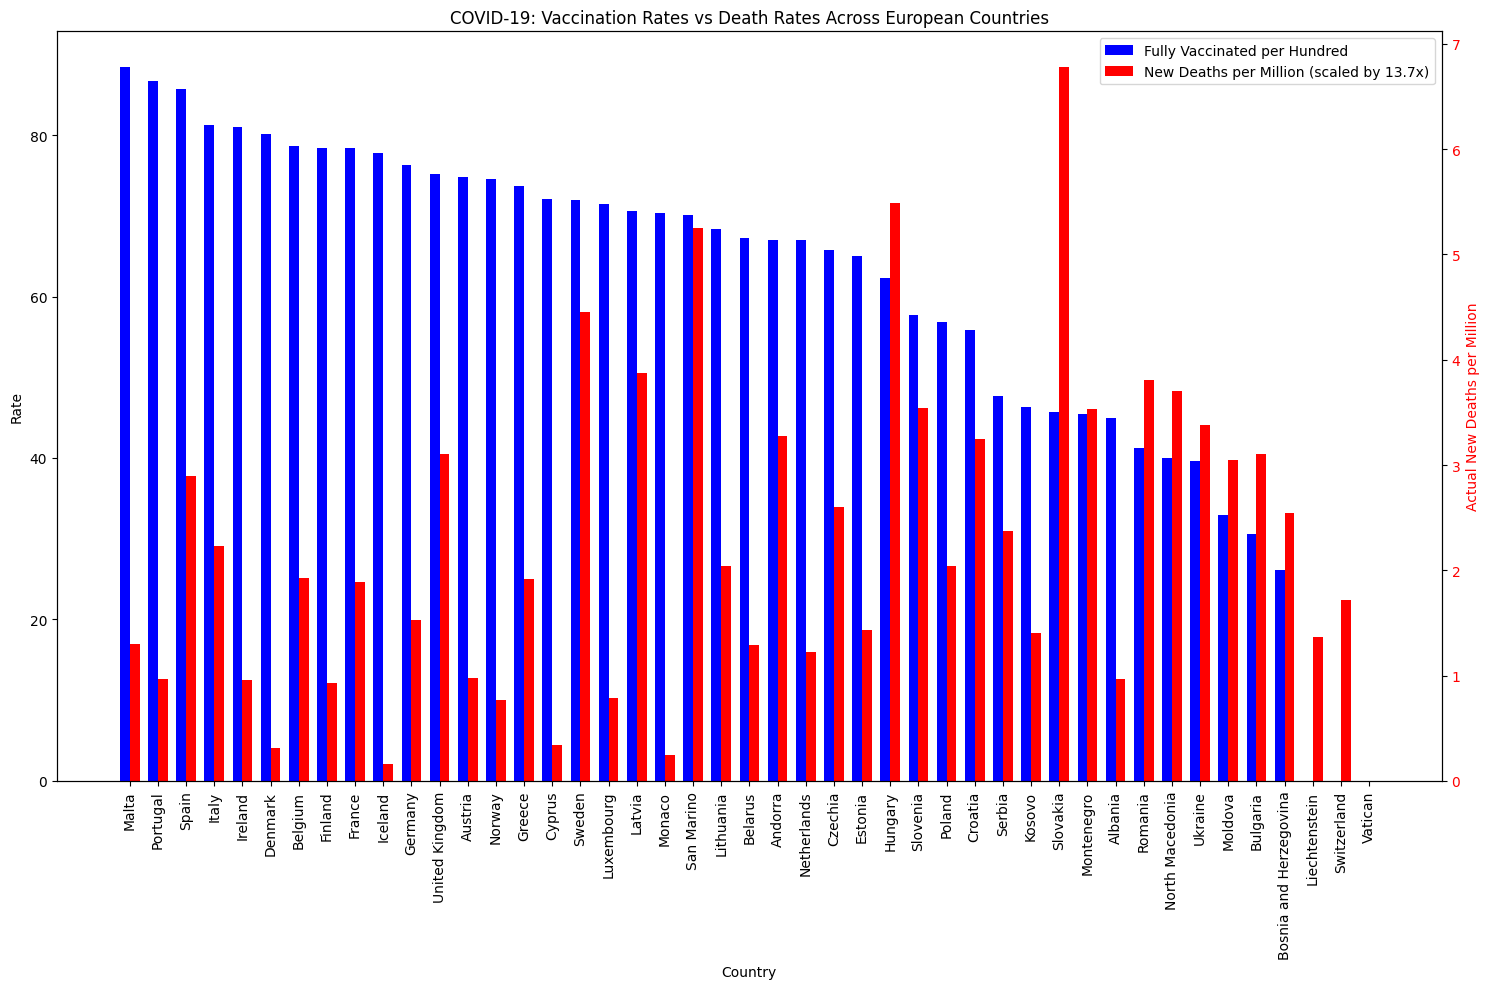

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

file_path = "europe_covid_cleaned.csv"
try:
    df = pd.read_csv(file_path)
    print("File loaded successfully with shape:", df.shape)
    
    df = df.dropna(subset=['people_fully_vaccinated_per_hundred', 'new_deaths_per_million', 'location'])
    
    aggregated_data = df.groupby('location').agg({
        'people_fully_vaccinated_per_hundred': 'max', 
        'new_deaths_per_million': 'mean'
    }).reset_index()
    
    aggregated_data = aggregated_data.sort_values('people_fully_vaccinated_per_hundred', ascending=False)
    
    plt.figure(figsize=(15, 10))
    
    bar_width = 0.35
    index = np.arange(len(aggregated_data))
    
    plt.bar(index, aggregated_data['people_fully_vaccinated_per_hundred'], 
            bar_width, color='b', label='Fully Vaccinated per Hundred')
    
    scale_factor = max(aggregated_data['people_fully_vaccinated_per_hundred']) / max(aggregated_data['new_deaths_per_million'])
    scaled_deaths = aggregated_data['new_deaths_per_million'] * scale_factor
    
    plt.bar(index + bar_width, scaled_deaths, 
            bar_width, color='r', label=f'New Deaths per Million (scaled by {scale_factor:.1f}x)')
    
    plt.xlabel('Country')
    plt.ylabel('Rate')
    plt.title('COVID-19: Vaccination Rates vs Death Rates Across European Countries')
    plt.xticks(index + bar_width/2, aggregated_data['location'], rotation=90)
    plt.legend()
    
    ax2 = plt.gca().twinx()
    ax2.set_ylabel('Actual New Deaths per Million', color='r')
    ax2.set_ylim(0, max(aggregated_data['new_deaths_per_million']) * 1.1)
    ax2.tick_params(axis='y', labelcolor='r')
    
    plt.tight_layout()
    
    plt.show()
    
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please check the file path.")
except Exception as e:
    print(f"An error occurred: {str(e)}")

### Scatterplot - GDP per Capita vs Deaths per Million (by Country)

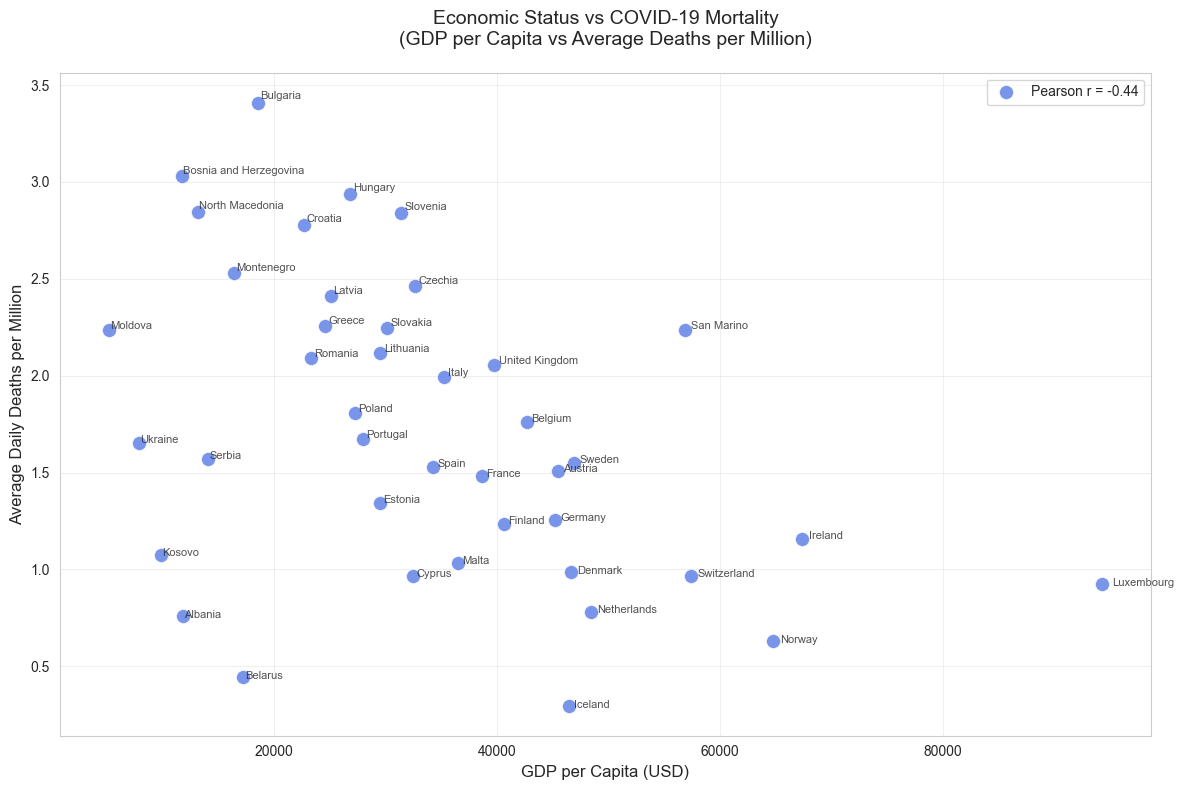

In [ ]:
gdp_death_df = df.dropna(subset=['gdp_per_capita', 'new_deaths_per_million', 'location'])

if not gdp_death_df.empty:
    country_stats = gdp_death_df.groupby('location').agg({
        'gdp_per_capita': 'mean',
        'new_deaths_per_million': 'mean'
    }).reset_index()
    
    plt.figure(figsize=(12, 8))
    
    plt.scatter(
        x=country_stats["gdp_per_capita"],
        y=country_stats["new_deaths_per_million"],
        s=100,
        alpha=0.7,
        color='royalblue',
        edgecolor='white',
        linewidth=0.5
    )
    
    for i, row in country_stats.iterrows():
        plt.text(
            x=row['gdp_per_capita'] * 1.01,
            y=row['new_deaths_per_million'] * 1.01,
            s=row['location'],
            fontsize=8,
            ha='left',
            va='center',
            alpha=0.8
        )
    
    plt.title("Economic Status vs COVID-19 Mortality\n(GDP per Capita vs Average Deaths per Million)",  fontsize=14, pad=20)
    plt.xlabel("GDP per Capita (USD)", fontsize=12)
    plt.ylabel("Average Daily Deaths per Million", fontsize=12)
    plt.grid(True, alpha=0.3)
    
    corr = country_stats['gdp_per_capita'].corr(country_stats['new_deaths_per_million'])
    plt.legend([f'Pearson r = {corr:.2f}'], loc='upper right', framealpha=0.8)
    
    plt.tight_layout()
    plt.show()
    
else:
    print("Insufficient data to create GDP vs Deaths analysis.")
    print("Missing either GDP per capita or deaths data for all countries.")